# Step 1. Read

*With ngff-zarr.*

One organoid was imaged in two rounds of staining, and it moved in between. The first round is the reference, the
**fixed** image. The second, the **moving** image, is the one to bring back onto it.

**Goal:** open both images and read only what you need, one resolution or one box, from disk or from a server.
`python steps/get_data.py` has put them in `output/data/`: the two rounds and their nuclei.

In [ ]:
import ngff_zarr as nz
from common import DATA, show

fixed = nz.from_ngff_zarr(f"{DATA}/fixed.ome.zarr")  # round 0, the reference
moving = nz.from_ngff_zarr(f"{DATA}/moving.ome.zarr")  # round 1, to bring onto it
for level, image in enumerate(fixed.images):
    print(f"level {level}: {image.data.shape} voxels of {image.scale['z']:.2g} x {image.scale['x']:.3g} µm, chunks {image.data.chunksize}")

level 0: (50, 680, 535) voxels of 0.6 x 0.217 µm, chunks (50, 128, 128)
level 1: (50, 340, 267) voxels of 0.6 x 0.433 µm, chunks (50, 128, 128)
level 2: (50, 170, 133) voxels of 0.6 x 0.867 µm, chunks (50, 128, 128)


**Opening reads the metadata, not the pixels.** Each image is a pyramid of three levels, each with its axes (z, y, x),
voxel size and unit. `image.data` is a dask array in chunks: computing a piece of it reads only the chunks it touches.

## Choose a resolution

The coarsest level is enough to see the whole organoid. One plane, the fixed round in green and the moving one in
magenta:

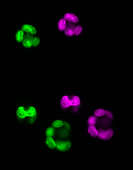

In [ ]:
show(fixed.images[2].data[25], moving.images[2].data[25])

The organoid moved between the two rounds: the two colours do not overlap.

## Or a box

To look closely, take a box of the full-resolution level. Only the chunks it touches are read:

9 chunks read, of 30


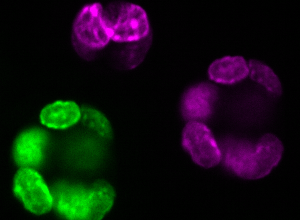

In [ ]:
box = fixed.images[0].data[25, 380:600, 170:470]  # one plane of level 0, a box of it
print(box.npartitions, "chunks read, of", fixed.images[0].data.npartitions)
show(box, moving.images[0].data[25, 380:600, 170:470])

## The same, on a server

A URL opens like a folder. The [mouse-embryo case](../use-cases/mouse-embryo/README.md) reads two time points of a
9.3 TB series on the IDR. Opening it and reading one box of its coarsest level takes a moment:

In [ ]:
series = nz.from_ngff_zarr("https://livingobjects.ebi.ac.uk/idr/zarr/v0.4/idr0044A/4007801.zarr")
print(series.images[0].data.shape, series.images[0].dims)
box = series.images[-1].data[150, 0, 494, 40:104, 40:104]  # time point 150, channel 0, the middle plane
print(box.npartitions, "chunk read, mean value", round(float(box.mean())))

(532, 2, 988, 2048, 2169) ('t', 'c', 'z', 'y', 'x')


1 chunk read, mean value 76


**Next: [Step 2. Register](2-register.ipynb)**